In [2]:
import pandas as pd
data=pd.read_csv("new_insurance_data.csv")

In [3]:
data

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.210,0.0,no,29087.54313,17.0,715428.0,4.720921e+06,0.0,5.578497e+07,southeast,1121.87390
1,18.0,male,30.140,0.0,no,39053.67437,7.0,699157.0,4.329832e+06,0.0,1.370089e+07,southeast,1131.50660
2,18.0,male,33.330,0.0,no,39023.62759,19.0,702341.0,6.884861e+06,0.0,7.352311e+07,southeast,1135.94070
3,18.0,male,33.660,0.0,no,28185.39332,11.0,700250.0,4.274774e+06,0.0,7.581968e+07,southeast,1136.39940
4,18.0,male,34.100,0.0,no,14697.85941,16.0,711584.0,3.787294e+06,0.0,2.301232e+07,southeast,1137.01100
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,33.0,female,35.530,0.0,yes,63142.25346,32.0,1091267.0,1.703805e+08,2.0,3.101107e+09,northwest,55135.40209
1334,31.0,female,38.095,1.0,yes,43419.95227,31.0,1107872.0,2.015152e+08,2.0,3.484216e+09,northeast,58571.07448
1335,52.0,male,34.485,3.0,yes,52458.92353,25.0,1092005.0,2.236450e+08,2.0,3.640807e+09,northwest,60021.39897
1336,45.0,male,30.360,0.0,yes,69927.51664,34.0,1106821.0,2.528924e+08,3.0,4.006359e+09,southeast,62592.87309


In [4]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [5]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

In [9]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error, 
    mean_absolute_percentage_error,
    r2_score
)


In [10]:
data.head()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


In [11]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 13 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   age                              1329 non-null   float64
 1   sex                              1338 non-null   str    
 2   bmi                              1335 non-null   float64
 3   children                         1333 non-null   float64
 4   smoker                           1338 non-null   str    
 5   Claim_Amount                     1324 non-null   float64
 6   past_consultations               1332 non-null   float64
 7   num_of_steps                     1335 non-null   float64
 8   Hospital_expenditure             1334 non-null   float64
 9   NUmber_of_past_hospitalizations  1336 non-null   float64
 10  Anual_Salary                     1332 non-null   float64
 11  region                           1338 non-null   str    
 12  charges                        

In [12]:
data.describe()

,age,bmi,children,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,charges
count,1329.000000,1335.000000,1333.000000,1324.000000,1332.000000,1.335000e+03,1.334000e+03,1336.000000,1.332000e+03,1338.000000
mean,39.310008,30.665112,1.090773,33361.327180,15.216216,9.100047e+05,1.584179e+07,1.060629,3.696849e+08,13270.422265
std,14.034818,6.101690,1.201856,15617.288337,7.467723,9.188612e+04,2.669305e+07,0.533583,5.668843e+08,12110.011237
min,18.000000,15.960000,0.000000,1920.136268,1.000000,6.954300e+05,2.945253e+04,0.000000,2.747072e+06,1121.873900
25%,27.000000,26.302500,0.000000,20768.860390,9.000000,8.471995e+05,4.077633e+06,1.000000,7.701932e+07,4740.287150
50%,39.000000,30.400000,1.000000,33700.310675,15.000000,9.143000e+05,7.490337e+06,1.000000,1.419361e+08,9382.033000
75%,51.000000,34.687500,2.000000,45052.331957,20.000000,9.716840e+05,1.084082e+07,1.000000,3.243499e+08,16639.912515
max,64.000000,53.130000,5.000000,77277.988480,40.000000,1.107872e+06,2.616317e+08,3.000000,4.117197e+09,63770.428010


In [13]:
data.tail()

,age,sex,bmi,children,smoker,Claim_Amount,past_consultations,num_of_steps,Hospital_expenditure,NUmber_of_past_hospitalizations,Anual_Salary,region,charges
1333,33.0,female,35.530,0.0,yes,63142.25346,32.0,1091267.0,170380500.5,2.0,3.101107e+09,northwest,55135.40209
1334,31.0,female,38.095,1.0,yes,43419.95227,31.0,1107872.0,201515184.8,2.0,3.484216e+09,northeast,58571.07448
1335,52.0,male,34.485,3.0,yes,52458.92353,25.0,1092005.0,223644981.3,2.0,3.640807e+09,northwest,60021.39897
1336,45.0,male,30.360,0.0,yes,69927.51664,34.0,1106821.0,252892382.6,3.0,4.006359e+09,southeast,62592.87309
1337,54.0,female,47.410,0.0,yes,63982.80926,31.0,1100328.0,261631699.3,3.0,4.117197e+09,southeast,63770.42801


In [30]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'claim_amount',
       'past_consultations', 'num_of_steps', 'hospital_expenditure',
       'number_of_past_hospitalizations', 'anual_salary', 'region', 'charges'],
      dtype='str')

In [31]:
data.columns=data.columns.str.lower()

In [32]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'claim_amount',
       'past_consultations', 'num_of_steps', 'hospital_expenditure',
       'number_of_past_hospitalizations', 'anual_salary', 'region', 'charges'],
      dtype='str')

In [33]:
data.rename(columns={'anual_salary':'annual_salary'})
data.head()

,age,sex,bmi,children,smoker,claim_amount,past_consultations,num_of_steps,hospital_expenditure,number_of_past_hospitalizations,anual_salary,region,charges
0,18.0,male,23.21,0.0,no,29087.54313,17.0,715428.0,4720920.992,0.0,55784970.05,southeast,1121.8739
1,18.0,male,30.14,0.0,no,39053.67437,7.0,699157.0,4329831.676,0.0,13700885.19,southeast,1131.5066
2,18.0,male,33.33,0.0,no,39023.62759,19.0,702341.0,6884860.774,0.0,73523107.27,southeast,1135.9407
3,18.0,male,33.66,0.0,no,28185.39332,11.0,700250.0,4274773.550,0.0,75819679.60,southeast,1136.3994
4,18.0,male,34.10,0.0,no,14697.85941,16.0,711584.0,3787293.921,0.0,23012320.01,southeast,1137.0110


In [34]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'claim_amount',
       'past_consultations', 'num_of_steps', 'hospital_expenditure',
       'number_of_past_hospitalizations', 'anual_salary', 'region', 'charges'],
      dtype='str')

In [35]:
data_categorical=data.select_dtypes(include=["object"])
data_categorical

,sex,smoker,region
0,male,no,southeast
1,male,no,southeast
2,male,no,southeast
3,male,no,southeast
4,male,no,southeast
...,...,...,...
1333,female,yes,northwest
1334,female,yes,northeast
1335,male,yes,northwest
1336,male,yes,southeast


In [36]:
data_numerical=data.select_dtypes(include=np.number)
data_numerical

,age,bmi,children,claim_amount,past_consultations,num_of_steps,hospital_expenditure,number_of_past_hospitalizations,anual_salary,charges
0,18.0,23.210,0.0,29087.54313,17.0,715428.0,4.720921e+06,0.0,5.578497e+07,1121.87390
1,18.0,30.140,0.0,39053.67437,7.0,699157.0,4.329832e+06,0.0,1.370089e+07,1131.50660
2,18.0,33.330,0.0,39023.62759,19.0,702341.0,6.884861e+06,0.0,7.352311e+07,1135.94070
3,18.0,33.660,0.0,28185.39332,11.0,700250.0,4.274774e+06,0.0,7.581968e+07,1136.39940
4,18.0,34.100,0.0,14697.85941,16.0,711584.0,3.787294e+06,0.0,2.301232e+07,1137.01100
...,...,...,...,...,...,...,...,...,...,...
1333,33.0,35.530,0.0,63142.25346,32.0,1091267.0,1.703805e+08,2.0,3.101107e+09,55135.40209
1334,31.0,38.095,1.0,43419.95227,31.0,1107872.0,2.015152e+08,2.0,3.484216e+09,58571.07448
1335,52.0,34.485,3.0,52458.92353,25.0,1092005.0,2.236450e+08,2.0,3.640807e+09,60021.39897
1336,45.0,30.360,0.0,69927.51664,34.0,1106821.0,2.528924e+08,3.0,4.006359e+09,62592.87309


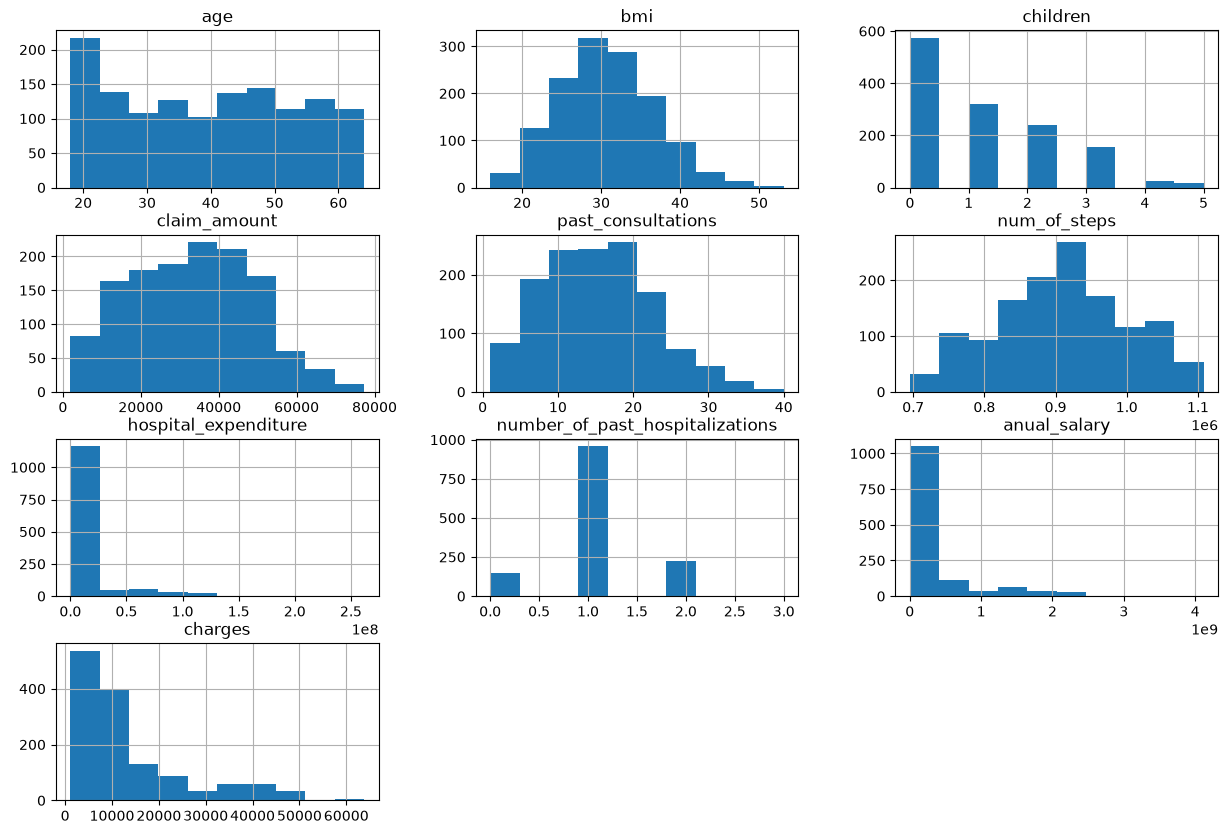

In [37]:
data_numerical.hist(figsize=(15,10))
plt.grid()
plt.show()


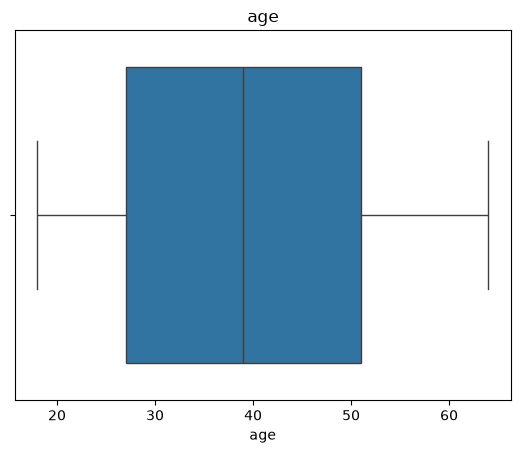

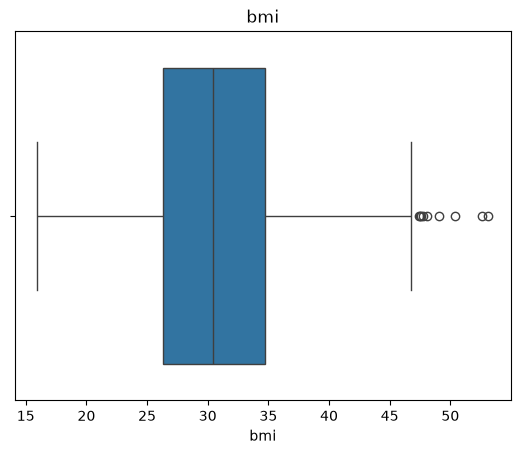

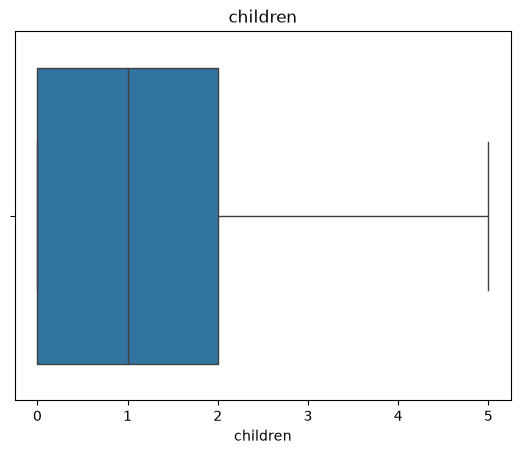

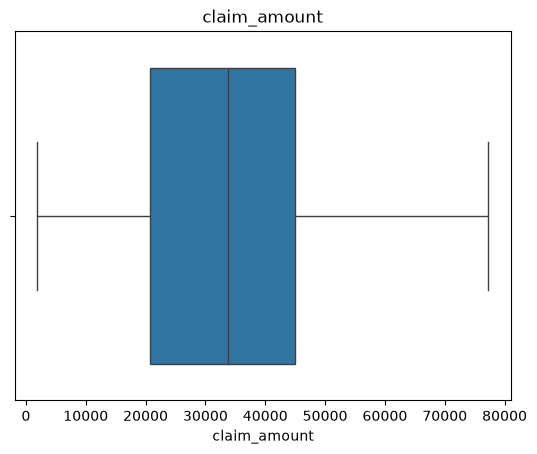

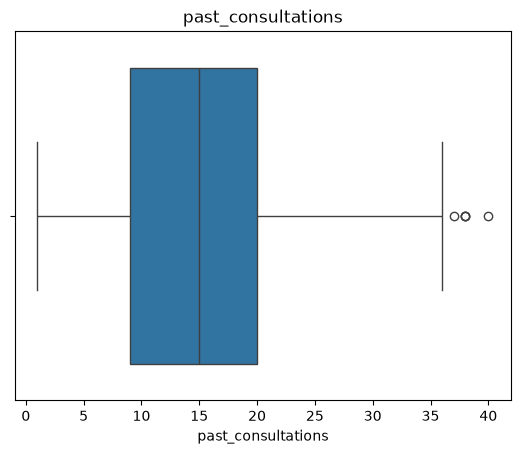

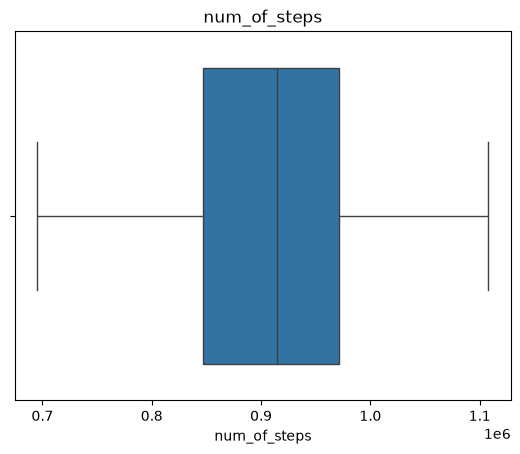

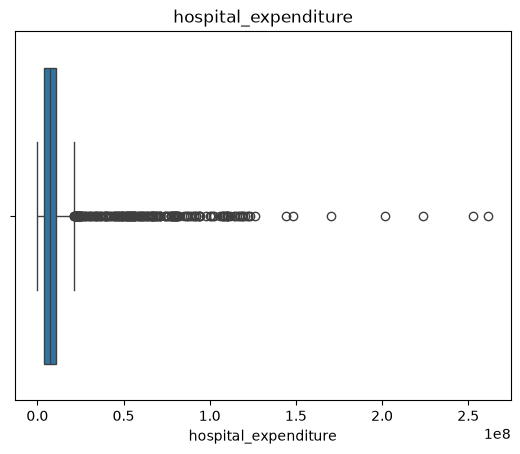

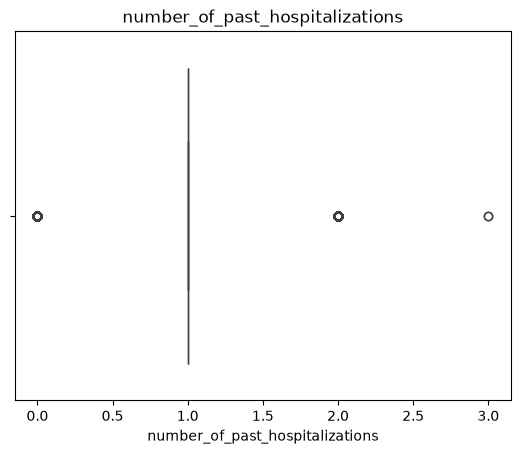

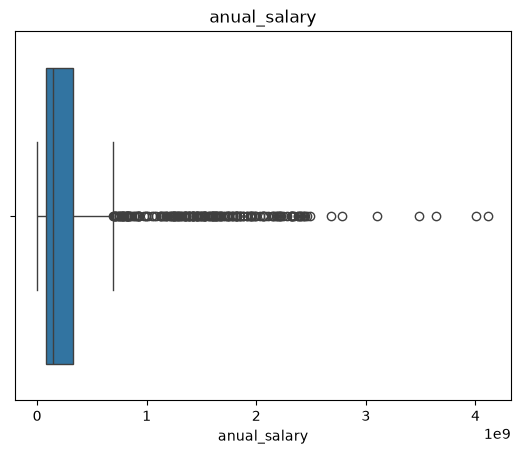

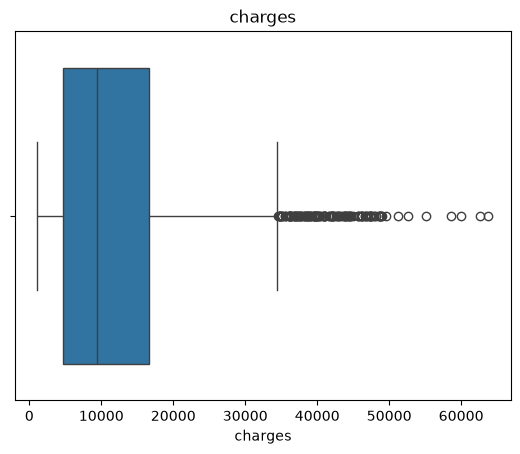

In [38]:
for col in data_numerical .columns:
    sns.figsize=(6,3)
    sns.boxplot(x=data_numerical[col])
    plt.title(f"{col}")
    plt.show()

In [39]:
data["children"].unique()

array([ 0.,  1.,  2.,  3.,  4.,  5., nan])

In [40]:
data["children"].value_counts()

children
0.0    574
1.0    321
2.0    240
3.0    156
4.0     25
5.0     17
Name: count, dtype: int64

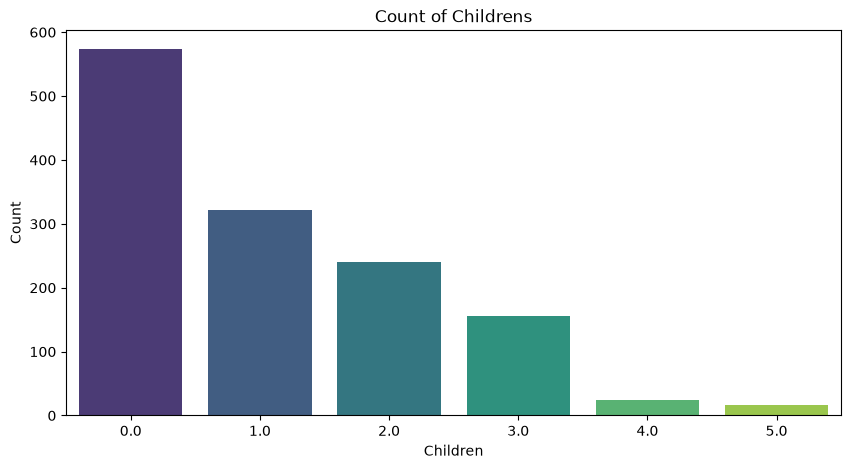

In [41]:
plt.figure(figsize=(10,5))
sns.countplot(x="children",data=data, palette=("viridis"))
plt.title("Count of Childrens")
plt.xlabel("Children")
plt.ylabel("Count")
plt.show()

In [42]:
data["number_of_past_hospitalizations"].unique()

array([ 0., nan,  1.,  2.,  3.])

In [43]:
data["number_of_past_hospitalizations"].value_counts()

number_of_past_hospitalizations
1.0    957
2.0    227
0.0    150
3.0      2
Name: count, dtype: int64

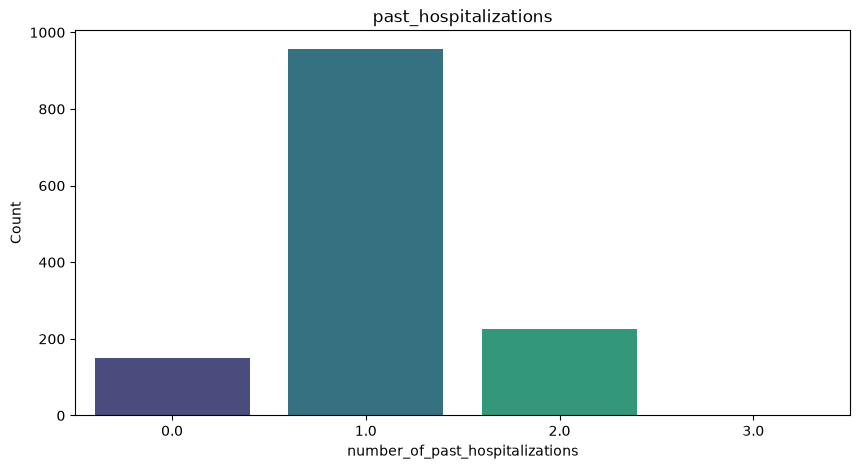

In [44]:
plt.figure(figsize=(10,5))
sns.countplot(x="number_of_past_hospitalizations",data=data, palette=("viridis"))
plt.title("past_hospitalizations")
plt.xlabel("number_of_past_hospitalizations")
plt.ylabel("Count")
plt.show()

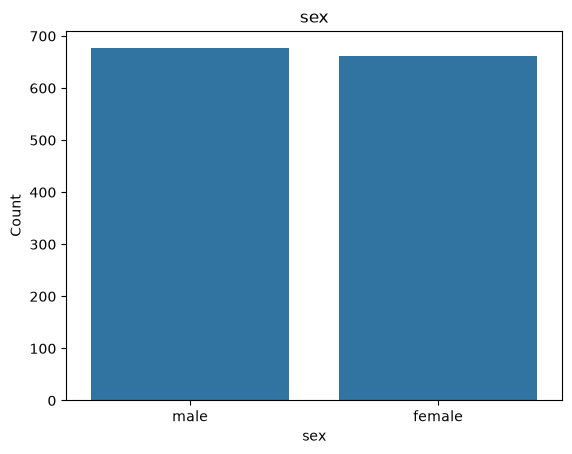

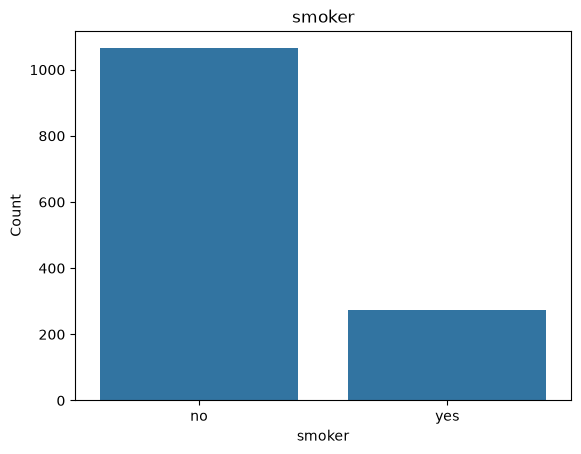

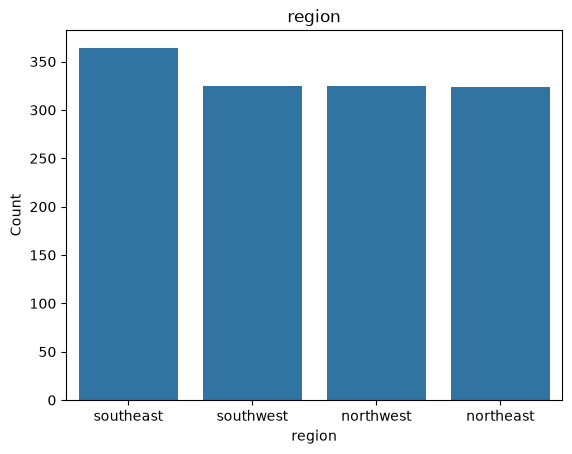

In [45]:
for col in data_categorical.columns:
    sns.figsize=(6,3)
    sns.countplot(x=col,data=data_categorical)
    plt.title(f"{col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [46]:
data.isnull().sum()

age                                 9
sex                                 0
bmi                                 3
children                            5
smoker                              0
claim_amount                       14
past_consultations                  6
num_of_steps                        3
hospital_expenditure                4
number_of_past_hospitalizations     2
anual_salary                        6
region                              0
charges                             0
dtype: int64

In [47]:
for col in data_numerical.columns:
    skew_value = data_numerical[col].skew()
    if -0.5 <= skew_value <=0.5:
        print(col,"-> use Mean")
    else:
        print(col,"->Use Meadian")

age -> use Mean
bmi -> use Mean
children ->Use Meadian
claim_amount -> use Mean
past_consultations -> use Mean
num_of_steps -> use Mean
hospital_expenditure ->Use Meadian
number_of_past_hospitalizations -> use Mean
anual_salary ->Use Meadian
charges ->Use Meadian


In [48]:
data_numerical.describe()

,age,bmi,children,claim_amount,past_consultations,num_of_steps,hospital_expenditure,number_of_past_hospitalizations,anual_salary,charges
count,1329.000000,1335.000000,1333.000000,1324.000000,1332.000000,1.335000e+03,1.334000e+03,1336.000000,1.332000e+03,1338.000000
mean,39.310008,30.665112,1.090773,33361.327180,15.216216,9.100047e+05,1.584179e+07,1.060629,3.696849e+08,13270.422265
std,14.034818,6.101690,1.201856,15617.288337,7.467723,9.188612e+04,2.669305e+07,0.533583,5.668843e+08,12110.011237
min,18.000000,15.960000,0.000000,1920.136268,1.000000,6.954300e+05,2.945253e+04,0.000000,2.747072e+06,1121.873900
25%,27.000000,26.302500,0.000000,20768.860390,9.000000,8.471995e+05,4.077633e+06,1.000000,7.701932e+07,4740.287150
50%,39.000000,30.400000,1.000000,33700.310675,15.000000,9.143000e+05,7.490337e+06,1.000000,1.419361e+08,9382.033000
75%,51.000000,34.687500,2.000000,45052.331957,20.000000,9.716840e+05,1.084082e+07,1.000000,3.243499e+08,16639.912515
max,64.000000,53.130000,5.000000,77277.988480,40.000000,1.107872e+06,2.616317e+08,3.000000,4.117197e+09,63770.428010


In [49]:
 data_numerical["age"].fillna(data_numerical["age"].mean(), inplace=True)

0       18.0
1       18.0
2       18.0
3       18.0
4       18.0
        ... 
1333    33.0
1334    31.0
1335    52.0
1336    45.0
1337    54.0
Name: age, Length: 1338, dtype: float64

In [50]:
for col in data_numerical.columns:
    skewness = data_numerical[col].skew()
    if abs(skewness) > 0.5:
        data_numerical[col]=data_numerical[col].fillna(data_numerical[col].median(), inplace=True)
    else:
        data_numerical[col]=data_numerical[col].fillna(data_numerical[col].mean(), inplace=True)
data_numerical.isnull().sum()

age                                0
bmi                                0
children                           0
claim_amount                       0
past_consultations                 0
num_of_steps                       0
hospital_expenditure               0
number_of_past_hospitalizations    0
anual_salary                       0
charges                            0
dtype: int64

In [51]:
data_categorical.isnull().sum()

sex       0
smoker    0
region    0
dtype: int64

In [52]:
data.duplicated().sum()

np.int64(0)

In [53]:
from sklearn.preprocessing import LabelEncoder

In [54]:
categorical_col=["sex","smoker","region"]

In [55]:
label_encoder=LabelEncoder()

In [56]:
for col in categorical_col:
    data_categorical[col]=label_encoder.fit_transform(data_categorical[col])
data_categorical

,sex,smoker,region
0,1,0,2
1,1,0,2
2,1,0,2
3,1,0,2
4,1,0,2
...,...,...,...
1333,0,1,1
1334,0,1,0
1335,1,1,1
1336,1,1,2


In [57]:
data.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'claim_amount',
       'past_consultations', 'num_of_steps', 'hospital_expenditure',
       'number_of_past_hospitalizations', 'anual_salary', 'region', 'charges'],
      dtype='str')

In [58]:
for col in ["bmi", "past_consultations", "hospital_expenditure","anual_salary"]:
    Q1 = data_numerical[col].quantile(0.25)
    Q3 = data_numerical[col].quantile(0.75)
    IQR=Q3-Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    data_numerical = data_numerical[(data_numerical[col] > lower_bound) & (data_numerical[col] < upper_bound)]
data_numerical

,age,bmi,children,claim_amount,past_consultations,num_of_steps,hospital_expenditure,number_of_past_hospitalizations,anual_salary,charges
0,18.0,23.210,0.0,29087.54313,17.0,715428.0,4.720921e+06,0.0,5.578497e+07,1121.87390
1,18.0,30.140,0.0,39053.67437,7.0,699157.0,4.329832e+06,0.0,1.370089e+07,1131.50660
2,18.0,33.330,0.0,39023.62759,19.0,702341.0,6.884861e+06,0.0,7.352311e+07,1135.94070
3,18.0,33.660,0.0,28185.39332,11.0,700250.0,4.274774e+06,0.0,7.581968e+07,1136.39940
4,18.0,34.100,0.0,14697.85941,16.0,711584.0,3.787294e+06,0.0,2.301232e+07,1137.01100
...,...,...,...,...,...,...,...,...,...,...
1046,29.0,27.940,1.0,51168.25474,23.0,993751.0,1.665982e+07,1.0,3.712188e+08,19107.77960
1048,31.0,25.900,3.0,46619.40230,27.0,989387.0,1.361938e+07,1.0,3.812895e+08,19199.94400
1050,31.0,29.810,0.0,24382.58056,21.0,973924.0,1.028991e+07,1.0,3.745310e+08,19350.36890
1062,43.0,20.045,2.0,21596.43846,10.0,994419.0,1.083030e+07,1.0,1.419361e+08,19798.05455


In [59]:
data.shape

(1338, 13)

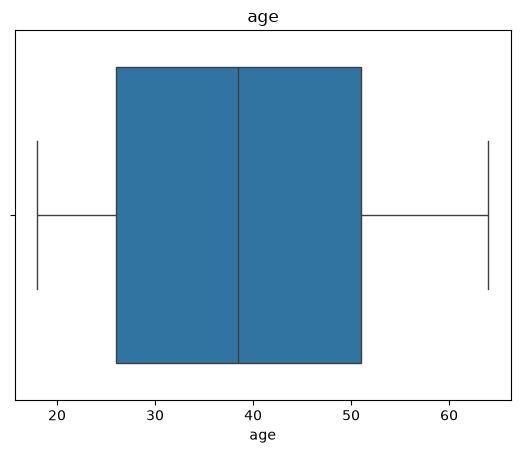

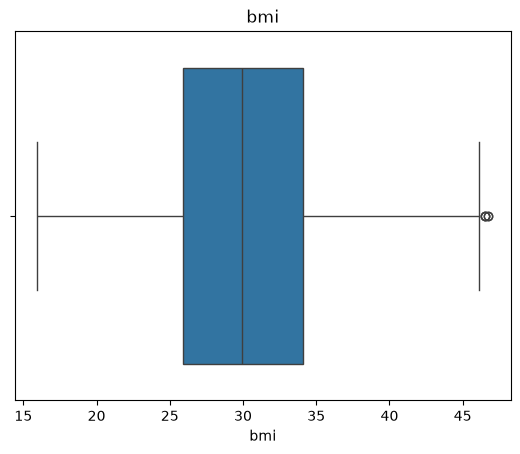

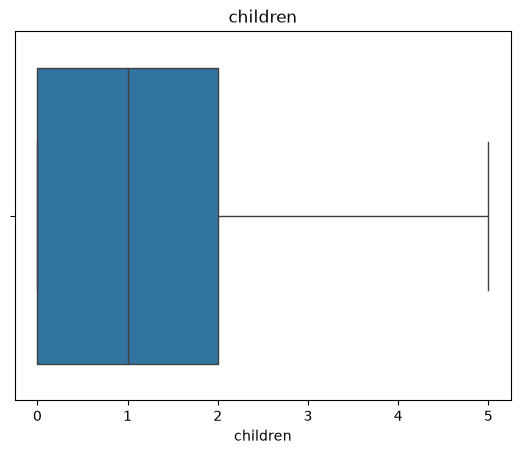

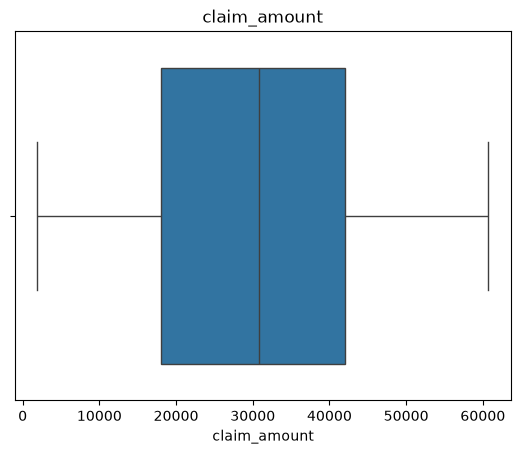

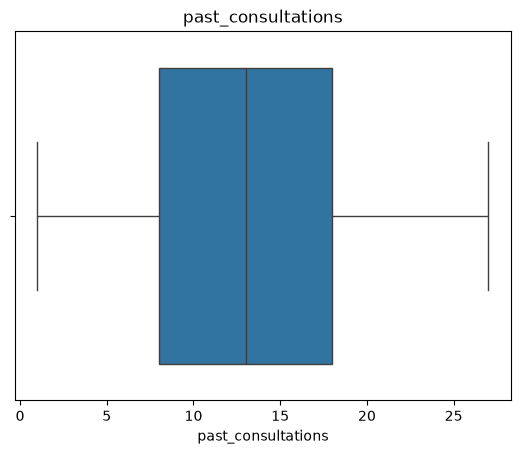

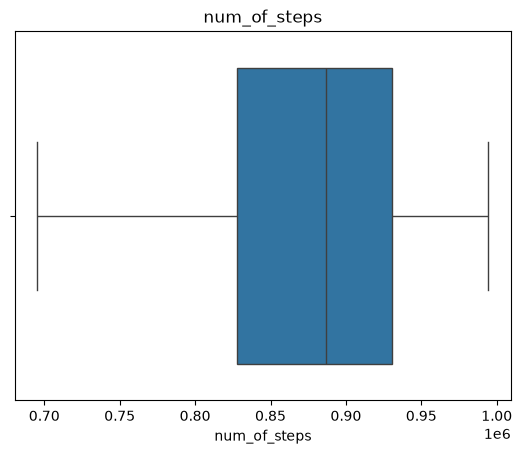

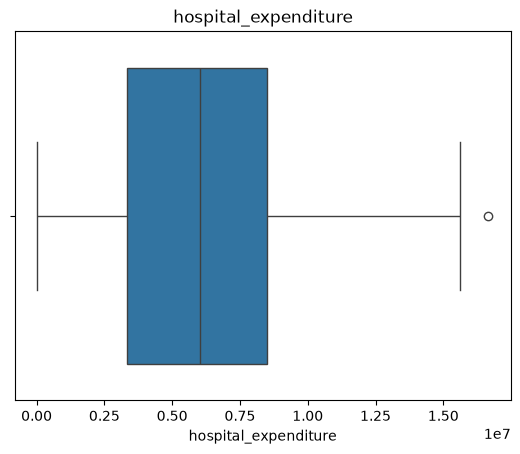

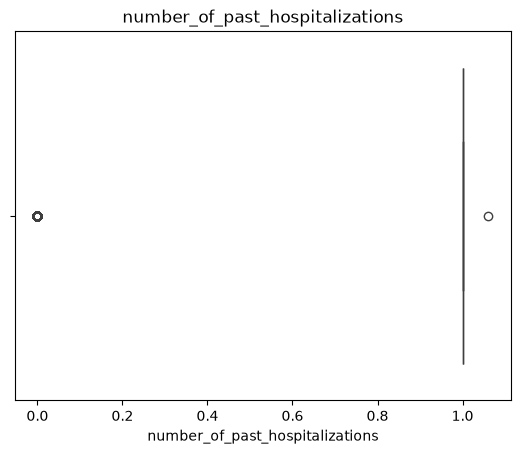

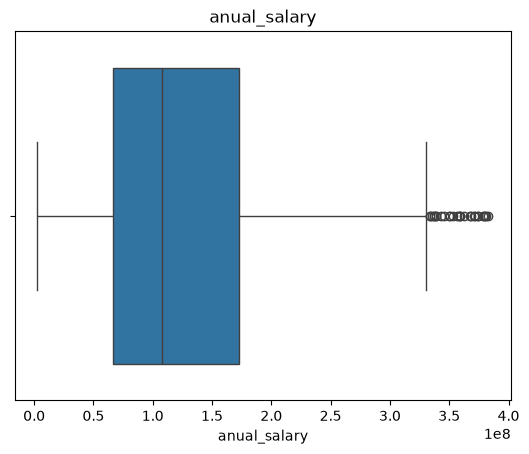

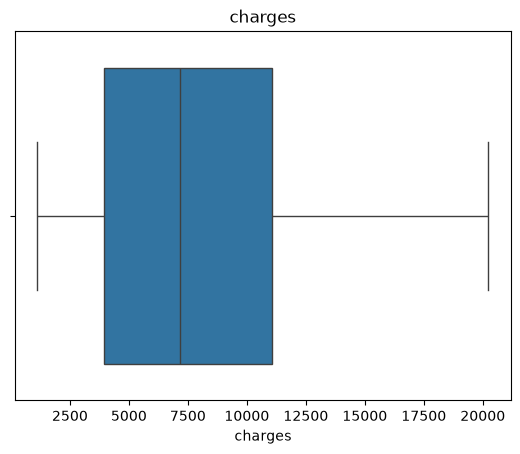

In [60]:
for col in data_numerical .columns:
    sns.figsize=(6,3)
    sns.boxplot(x=data_numerical[col])
    plt.title(f"{col}")
    plt.show()

In [61]:
data_numerical.corr()

,age,bmi,children,claim_amount,past_consultations,num_of_steps,hospital_expenditure,number_of_past_hospitalizations,anual_salary,charges
age,1.000000,0.155957,0.045569,0.117750,0.172063,0.749468,0.166923,0.519538,0.506958,0.676071
bmi,0.155957,1.000000,0.006231,0.008343,0.023543,0.040324,0.017145,0.016121,0.006511,0.010248
children,0.045569,0.006231,1.000000,0.041953,0.045568,0.228949,-0.007008,0.316471,0.071375,0.138682
claim_amount,0.117750,0.008343,0.041953,1.000000,0.071569,0.185434,0.052279,0.109748,0.168878,0.192601
past_consultations,0.172063,0.023543,0.045568,0.071569,1.000000,0.259401,0.089657,0.135498,0.267111,0.278131
num_of_steps,0.749468,0.040324,0.228949,0.185434,0.259401,1.000000,0.310650,0.714983,0.783088,0.936946
hospital_expenditure,0.166923,0.017145,-0.007008,0.052279,0.089657,0.310650,1.000000,0.135239,0.374759,0.368815
number_of_past_hospitalizations,0.519538,0.016121,0.316471,0.109748,0.135498,0.714983,0.135239,1.000000,0.376874,0.538116
anual_salary,0.506958,0.006511,0.071375,0.168878,0.267111,0.783088,0.374759,0.376874,1.000000,0.900466
charges,0.676071,0.010248,0.138682,0.192601,0.278131,0.936946,0.368815,0.538116,0.900466,1.000000


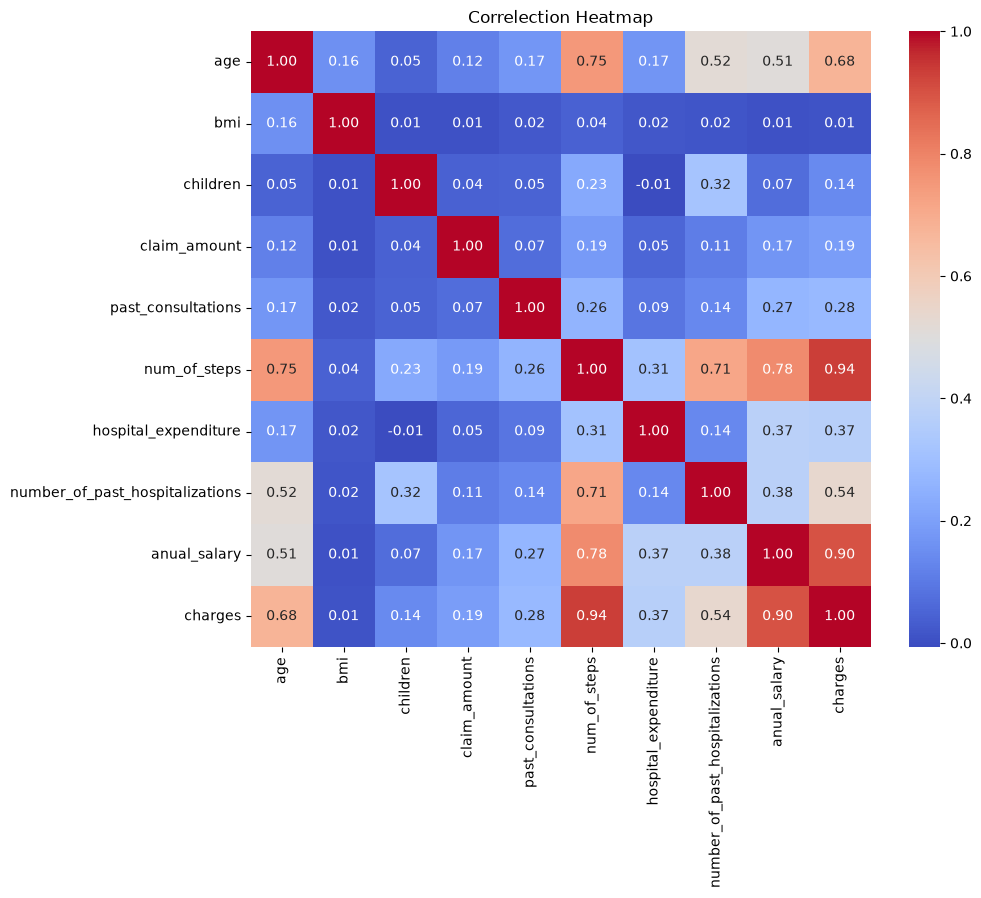

In [62]:
plt.figure(figsize=(10,8))
sns.heatmap(data_numerical.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlection Heatmap")
plt.show()

In [63]:
# prompt: drop bmi

data_numerical= data_numerical.drop('bmi', axis=1)


In [64]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


In [65]:
# prompt: VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Separate features (X) and target (y)
X = data_numerical.drop('charges', axis=1).dropna()  # Replace 'charges' with your target variable name

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Print VIF values
vif_data


,feature,VIF
0,age,2.556889
1,children,1.183157
2,claim_amount,1.039075
3,past_consultations,1.086723
4,num_of_steps,8.697092
5,hospital_expenditure,1.176861
6,number_of_past_hospitalizations,2.590961
7,anual_salary,3.499070


In [66]:
data_numerical = data_numerical.drop('num_of_steps', axis=1).dropna()

In [67]:
data_numerical.columns

Index(['age', 'children', 'claim_amount', 'past_consultations',
       'hospital_expenditure', 'number_of_past_hospitalizations',
       'anual_salary', 'charges'],
      dtype='str')

In [68]:
# Separate features (X) and target (y)
# Replace 'charges' with your target variable name
X = data_numerical.drop('charges', axis=1).dropna() 

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Print VIF values
vif_data

,feature,VIF
0,age,1.655171
1,children,1.138391
2,claim_amount,1.033444
3,past_consultations,1.080728
4,hospital_expenditure,1.166532
5,number_of_past_hospitalizations,1.587473
6,anual_salary,1.638802


In [69]:
data_numerical = data_numerical.drop('age', axis=1).dropna()

In [70]:
data_numerical.columns

Index(['children', 'claim_amount', 'past_consultations',
       'hospital_expenditure', 'number_of_past_hospitalizations',
       'anual_salary', 'charges'],
      dtype='str')

In [71]:

# Separate features (X) and target (y)
X = data_numerical.drop('charges', axis=1).dropna()  # Replace 'charges' with your target variable name

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Print VIF values
vif_data

,feature,VIF
0,children,1.116585
1,claim_amount,1.033037
2,past_consultations,1.079587
3,hospital_expenditure,1.165245
4,number_of_past_hospitalizations,1.296203
5,anual_salary,1.426848


In [72]:
print(vif_data.dtypes)

feature        str
VIF        float64
dtype: object


In [73]:
vif_data = vif_data.select_dtypes(include="number")

In [74]:
vif_data.corr()

,VIF
VIF,1.0


In [75]:
data_categorical.head()

,sex,smoker,region
0,1,0,2
1,1,0,2
2,1,0,2
3,1,0,2
4,1,0,2


In [76]:
# Align df_cat to the indices of X (which contains the rows remaining after outlier removal)
data_categorical_aligned = data_categorical.loc[X.index]

# Concatenate the aligned df_cat and X
X= pd.concat([data_categorical_aligned, X], axis=1)

print("Shape of the combined DataFrame (df_cat_aligned and X):")
print(X.shape)
display(X.head())

Shape of the combined DataFrame (df_cat_aligned and X):
(1030, 9)


,sex,smoker,region,children,claim_amount,past_consultations,hospital_expenditure,number_of_past_hospitalizations,anual_salary
0,1,0,2,0.0,29087.54313,17.0,4720920.992,0.0,55784970.05
1,1,0,2,0.0,39053.67437,7.0,4329831.676,0.0,13700885.19
2,1,0,2,0.0,39023.62759,19.0,6884860.774,0.0,73523107.27
3,1,0,2,0.0,28185.39332,11.0,4274773.550,0.0,75819679.60
4,1,0,2,0.0,14697.85941,16.0,3787293.921,0.0,23012320.01


In [77]:
X.isnull().sum().sum()

np.int64(0)

In [78]:
X.duplicated().sum()

np.int64(0)

In [79]:
data_numerical.columns

Index(['children', 'claim_amount', 'past_consultations',
       'hospital_expenditure', 'number_of_past_hospitalizations',
       'anual_salary', 'charges'],
      dtype='str')

In [80]:
X= pd.concat([data_numerical['charges'], X], axis=1)

print("Shape of the combined DataFrame (df_cat_aligned and X):")
print(X.shape)
display(X.head())

Shape of the combined DataFrame (df_cat_aligned and X):
(1030, 10)


,charges,sex,smoker,region,children,claim_amount,past_consultations,hospital_expenditure,number_of_past_hospitalizations,anual_salary
0,1121.8739,1,0,2,0.0,29087.54313,17.0,4720920.992,0.0,55784970.05
1,1131.5066,1,0,2,0.0,39053.67437,7.0,4329831.676,0.0,13700885.19
2,1135.9407,1,0,2,0.0,39023.62759,19.0,6884860.774,0.0,73523107.27
3,1136.3994,1,0,2,0.0,28185.39332,11.0,4274773.550,0.0,75819679.60
4,1137.0110,1,0,2,0.0,14697.85941,16.0,3787293.921,0.0,23012320.01


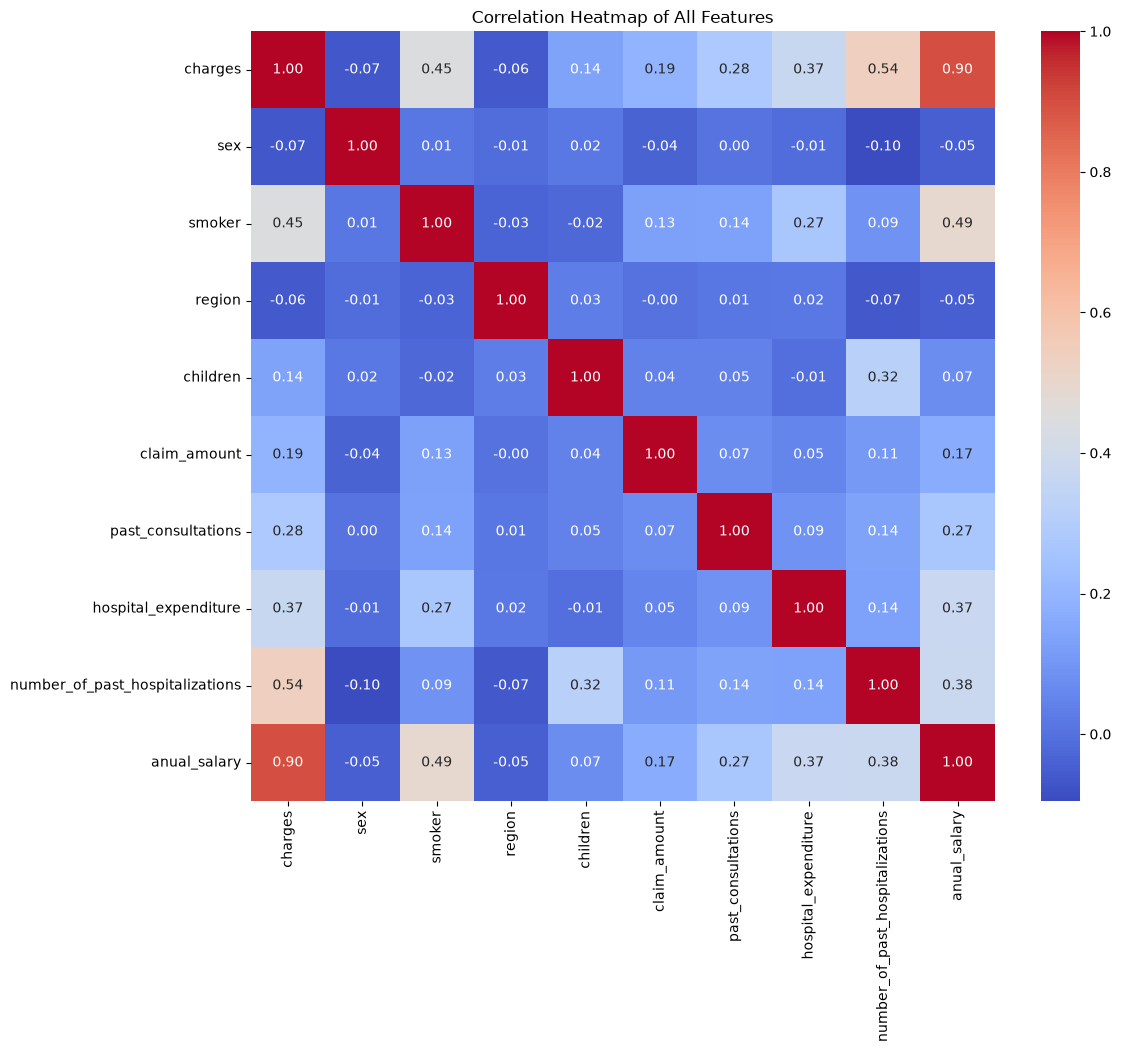

In [81]:
# prompt: corr()

import matplotlib.pyplot as plt
X.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of All Features')
plt.show()


In [82]:
# prompt: groupby smoker with charges agg mean

df_grouped = X.groupby('smoker')['charges'].mean()
df_grouped


smoker
0     7235.044417
1    16824.395908
Name: charges, dtype: float64

In [83]:
# prompt: ttest for smoker
#H0- No significant difference between means of two groups
#H1- Significant Differencet between means of two groups
from scipy.stats import ttest_ind

# Separate charges for smokers and non-smokers
smoker_charges = X[X['smoker'] == 1]['charges']
non_smoker_charges = X[X['smoker'] == 0]['charges']

# Perform independent t-test
ttest_result = ttest_ind(smoker_charges, non_smoker_charges)

# Print the results
print("Independent t-test for Charges based on Smoker Status:")
print(f"Mean Charges for Smokers: {smoker_charges.mean():.2f}")
print(f"Mean Charges for Non-Smokers: {non_smoker_charges.mean():.2f}")
print(f"T-statistic: {ttest_result.statistic:.4f}")
print(f"P-value: {ttest_result.pvalue:.4f}")

# Interpret the results
alpha = 0.05
if ttest_result.pvalue < alpha:
    print("Reject Null Hypothesis")
    print("The difference in mean charges between smokers and non-smokers is statistically significant.")
else:
    print("Fail to Reject Null Hypothesis")
    print("There is no statistically significant difference in mean charges between smokers and non-smokers.")


Independent t-test for Charges based on Smoker Status:
Mean Charges for Smokers: 16824.40
Mean Charges for Non-Smokers: 7235.04
T-statistic: 15.9666
P-value: 0.0000
Reject Null Hypothesis
The difference in mean charges between smokers and non-smokers is statistically significant.


In [84]:
# prompt: groupby sex with charges

df_grouped_sex = X.groupby('sex')['charges'].mean()
print(df_grouped_sex)

# Separate charges by sex
male_charges = X[X['sex'] == 1]['charges']
female_charges = X[X['sex'] == 0]['charges']

# Perform independent t-test
ttest_result_sex = ttest_ind(male_charges, female_charges)

# Print the results
print("\nIndependent t-test for Charges based on Sex:")
print(f"Mean Charges for Males: {male_charges.mean():.2f}")
print(f"Mean Charges for Females: {female_charges.mean():.2f}")
print(f"T-statistic: {ttest_result_sex.statistic:.4f}")
print(f"P-value: {ttest_result_sex.pvalue:.4f}")

# Interpret the results
alpha = 0.05
if ttest_result_sex.pvalue < alpha:
    print("The difference in mean charges between males and females is statistically significant.")
else:
    print("There is no statistically significant difference in mean charges between males and females.")


sex
0    7934.605729
1    7355.392634
Name: charges, dtype: float64

Independent t-test for Charges based on Sex:
Mean Charges for Males: 7355.39
Mean Charges for Females: 7934.61
T-statistic: -2.1153
P-value: 0.0346
The difference in mean charges between males and females is statistically significant.


In [85]:
# prompt: regions

df_grouped_region = X.groupby('region')['charges'].mean()
df_grouped_region


region
0    8222.611041
1    7610.525050
2    7237.087863
3    7569.342351
Name: charges, dtype: float64

In [86]:
# prompt: interpretation with anova test with region and charges whether it is a good predictor or not

# Interpretation with ANOVA test for region and charges
# Based on the provided code snippet

from scipy import stats

# Perform one-way ANOVA test
anova_result = stats.f_oneway(
    X['charges'][X['region'] == 0],
    X['charges'][X['region'] == 1],
    X['charges'][X['region'] == 2],
    X['charges'][X['region'] == 3]
)

# Print the ANOVA result
print("ANOVA Result:")
print(f"F-statistic: {anova_result.statistic:.4f}")
print(f"P-value: {anova_result.pvalue:.4f}")

# Interpretation:
# The ANOVA test is used to determine if there are any statistically significant
# differences between the means of two or more independent groups.
# In this case, the groups are the different regions, and the variable being
# compared is 'charges'.
# The null hypothesis (H0) is that the mean charges are equal across all regions.
# The alternative hypothesis (H1) is that at least one region has a different
# mean charge.

# Significance level (alpha) is typically set at 0.05.
alpha = 0.05

# Compare the p-value from the ANOVA test with the significance level.
if anova_result.pvalue < alpha:
    print("\nInterpretation: The p-value is less than the significance level (0.05).")
    print("We reject the null hypothesis.")
    print("This indicates that there is a statistically significant difference in the mean charges among the different regions.")
    print("Therefore, 'region' is likely a good predictor of 'charges'.")
else:
    print("\nInterpretation: The p-value is greater than the significance level (0.05).")
    print("We fail to reject the null hypothesis.")
    print("This indicates that there is no statistically significant difference in the mean charges among the different regions.")
    print("Therefore, 'region' is likely not a good predictor of 'charges' based on this test.")

ANOVA Result:
F-statistic: 2.2108
P-value: 0.0853

Interpretation: The p-value is greater than the significance level (0.05).
We fail to reject the null hypothesis.
This indicates that there is no statistically significant difference in the mean charges among the different regions.
Therefore, 'region' is likely not a good predictor of 'charges' based on this test.


In [87]:
# Group by 'children' and calculate the mean of 'charges'
df_grouped_children = X.groupby('children')['charges'].mean()
print("Mean Charges by Number of Children:")
display(df_grouped_children)

Mean Charges by Number of Children:


children
0.0     7241.575859
1.0     7290.625943
2.0     8002.255373
3.0     9032.232897
4.0    10193.150916
5.0     8393.421528
Name: charges, dtype: float64

In [88]:
from scipy import stats

# Prepare data for ANOVA
# Get unique values of 'children'
children_groups = X['children'].unique()

# Create a list of charges for each children group
charges_by_children_group = [X['charges'][X['children'] == group] for group in children_groups]

# Perform one-way ANOVA test
anova_result_children = stats.f_oneway(*charges_by_children_group)

# Print the ANOVA result
print("\nANOVA Result for Charges based on Number of Children:")
print(f"F-statistic: {anova_result_children.statistic:.4f}")
print(f"P-value: {anova_result_children.pvalue:.4f}")

# Interpret the results
alpha = 0.05
if anova_result_children.pvalue < alpha:
    print("\nInterpretation: The p-value is less than the significance level (0.05).")
    print("We reject the null hypothesis.")
    print("This indicates that there is a statistically significant difference in the mean charges among different numbers of children.")
    print("Therefore, 'children' is likely a good predictor of 'charges'.")
else:
    print("\nInterpretation: The p-value is greater than the significance level (0.05).")
    print("We fail to reject the null hypothesis.")
    print("This indicates that there is no statistically significant difference in the mean charges among different numbers of children.")
    print("Therefore, 'children' is likely not a good predictor of 'charges' based on this test.")


ANOVA Result for Charges based on Number of Children:
F-statistic: 5.1223
P-value: 0.0001

Interpretation: The p-value is less than the significance level (0.05).
We reject the null hypothesis.
This indicates that there is a statistically significant difference in the mean charges among different numbers of children.
Therefore, 'children' is likely a good predictor of 'charges'.


In [89]:
# Group by 'number_of_past_hospitalizations' and calculate the mean of 'charges'
df_grouped_hospitalizations = X.groupby('number_of_past_hospitalizations')['charges'].mean()
print("Mean Charges by Number of Past Hospitalizations:")
display(df_grouped_hospitalizations)

Mean Charges by Number of Past Hospitalizations:


number_of_past_hospitalizations
0.000000    1874.641698
1.000000    8632.152984
1.060629    1242.816000
Name: charges, dtype: float64

In [90]:
from scipy import stats

# Prepare data for ANOVA
# Get unique values of 'number_of_past_hospitalizations'
hospitalization_groups = X['number_of_past_hospitalizations'].unique()

# Create a list of charges for each hospitalization group
charges_by_hospitalization_group = [X['charges'][X['number_of_past_hospitalizations'] == group] for group in hospitalization_groups]

# Perform one-way ANOVA test
anova_result_hospitalizations = stats.f_oneway(*charges_by_hospitalization_group)

# Print the ANOVA result
print("\nANOVA Result for Charges based on Number of Past Hospitalizations:")
print(f"F-statistic: {anova_result_hospitalizations.statistic:.4f}")
print(f"P-value: {anova_result_hospitalizations.pvalue:.4f}")

# Interpret the results
alpha = 0.05
if anova_result_hospitalizations.pvalue < alpha:
    print("\nInterpretation: The p-value is less than the significance level (0.05).")
    print("We reject the null hypothesis.")
    print("This indicates that there is a statistically significant difference in the mean charges among different numbers of past hospitalizations.")
    print("Therefore, 'number_of_past_hospitalizations' is likely a good predictor of 'charges'.")
else:
    print("\nInterpretation: The p-value is greater than the significance level (0.05).")
    print("We fail to reject the null hypothesis.")
    print("This indicates that there is no statistically significant difference in the mean charges among different numbers of past hospitalizations.")
    print("Therefore, 'number_of_past_hospitalizations' is likely not a good predictor of 'charges' based on this test.")


ANOVA Result for Charges based on Number of Past Hospitalizations:
F-statistic: 212.4170
P-value: 0.0000

Interpretation: The p-value is less than the significance level (0.05).
We reject the null hypothesis.
This indicates that there is a statistically significant difference in the mean charges among different numbers of past hospitalizations.
Therefore, 'number_of_past_hospitalizations' is likely a good predictor of 'charges'.


In [91]:
# prompt: drop region and sex
X = X.drop(['region'], axis=1)


In [92]:
X.head()

,charges,sex,smoker,children,claim_amount,past_consultations,hospital_expenditure,number_of_past_hospitalizations,anual_salary
0,1121.8739,1,0,0.0,29087.54313,17.0,4720920.992,0.0,55784970.05
1,1131.5066,1,0,0.0,39053.67437,7.0,4329831.676,0.0,13700885.19
2,1135.9407,1,0,0.0,39023.62759,19.0,6884860.774,0.0,73523107.27
3,1136.3994,1,0,0.0,28185.39332,11.0,4274773.550,0.0,75819679.60
4,1137.0110,1,0,0.0,14697.85941,16.0,3787293.921,0.0,23012320.01


In [93]:
# prompt: save to_csv as Preprocessed Linear Charges

X.to_csv('Preprocessed Charges.csv', index=False)


In [94]:
df_processed = pd.read_csv('Preprocessed Charges.csv')
df_processed.head()

,charges,sex,smoker,children,claim_amount,past_consultations,hospital_expenditure,number_of_past_hospitalizations,anual_salary
0,1121.8739,1,0,0.0,29087.54313,17.0,4720920.992,0.0,55784970.05
1,1131.5066,1,0,0.0,39053.67437,7.0,4329831.676,0.0,13700885.19
2,1135.9407,1,0,0.0,39023.62759,19.0,6884860.774,0.0,73523107.27
3,1136.3994,1,0,0.0,28185.39332,11.0,4274773.550,0.0,75819679.60
4,1137.0110,1,0,0.0,14697.85941,16.0,3787293.921,0.0,23012320.01


In [95]:
df_processed.tail()

,charges,sex,smoker,children,claim_amount,past_consultations,hospital_expenditure,number_of_past_hospitalizations,anual_salary
1025,19107.77960,0,1,1.0,51168.25474,23.0,16659821.70,1.0,371218761.2
1026,19199.94400,1,1,3.0,46619.40230,27.0,13619378.07,1.0,381289534.6
1027,19350.36890,1,1,0.0,24382.58056,21.0,10289906.76,1.0,374530950.6
1028,19798.05455,0,1,2.0,21596.43846,10.0,10830301.14,1.0,141936093.2
1029,20234.85475,0,1,0.0,17200.14586,15.0,12477443.06,1.0,141936093.2


In [96]:
df_processed.shape

(1030, 9)

In [97]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler

In [98]:
df_processed = pd.read_csv('Preprocessed Charges.csv')


In [99]:
df_processed.head()

,charges,sex,smoker,children,claim_amount,past_consultations,hospital_expenditure,number_of_past_hospitalizations,anual_salary
0,1121.8739,1,0,0.0,29087.54313,17.0,4720920.992,0.0,55784970.05
1,1131.5066,1,0,0.0,39053.67437,7.0,4329831.676,0.0,13700885.19
2,1135.9407,1,0,0.0,39023.62759,19.0,6884860.774,0.0,73523107.27
3,1136.3994,1,0,0.0,28185.39332,11.0,4274773.550,0.0,75819679.60
4,1137.0110,1,0,0.0,14697.85941,16.0,3787293.921,0.0,23012320.01


In [100]:
X=df_processed.drop("charges",axis=1)
y=df_processed["charges"]

In [101]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(824, 8) (206, 8)


In [102]:
print(y_train.shape, y_test.shape)

(824,) (206,)


# Scalling

In [103]:
scaler=StandardScaler()
X_train_s=scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print(X_train_s)


[[-0.99757575  4.89588572 -0.87468497 ...  2.09023469  0.40452013
   2.18067167]
 [ 1.00243014 -0.20425313 -0.87468497 ...  0.74913566  0.40452013
  -0.65728228]
 [ 1.00243014 -0.20425313 -0.05844441 ... -1.70359471  0.40452013
  -0.88749842]
 ...
 [ 1.00243014 -0.20425313  1.57403671 ...  0.9903275   0.40452013
   0.02767435]
 [-0.99757575 -0.20425313 -0.87468497 ... -0.77572561 -2.47047031
  -1.10003999]
 [ 1.00243014 -0.20425313 -0.05844441 ...  0.04811103  0.40452013
   0.51512462]]


In [104]:
model = LinearRegression()

In [105]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[-0., 0., 0.,..., 0., 0., 0.]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['sex','smoker','children',...,'hospital_expenditure', 'number_of_past_hospitalizations','anual_salary']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,980.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,3


In [106]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error, 
    mean_absolute_percentage_error,
    r2_score
)


In [107]:
y_pred= model.predict(X_test)
print(y_pred)

[ 5038.32859488  1879.31931608  4115.43398466  3234.2098311
 14679.7346434  20139.30461288 11264.14417734  2305.17595378
  4434.40747236  7460.44252716 11155.96689469  5793.57925425
  3186.13537515  5127.28168617  4896.04286088  5414.28892114
 10522.34235628  7912.08280243  8342.27975224  5053.48216604
  5471.05180853  4542.22439137  5993.29293663  6166.69752962
  5286.31340885  4889.87874693  7204.29155189 15367.59516464
  4803.43099894  5711.34190871  5061.49707863  5415.55846639
 10603.40898193  6280.37191852  4435.03635178  2448.71781676
  5618.18495403 15735.50718351  6636.76403383  5040.42203815
  8114.99809226  8064.58744608  1260.35703668  8426.09175478
  4914.58048526  4367.93392729  3718.94308294  8891.57433557
 11121.38148585 10012.04828794 13351.36593934  7593.20917389
 11081.76373048  7841.32232205  4121.11380664  1643.56307038
  4795.2949544  11328.99689566  4766.12419195  9018.88733821
 11518.0452006  10050.49540458  6572.64437913  5626.12302258
  9641.13355953  9755.001

In [108]:
mse = mean_squared_error(y_test,y_pred)

In [109]:
print(mse)

3712415.406724196


In [110]:
print(round(mse))

3712415


In [111]:
mae = mean_absolute_error(y_test,y_pred)

In [112]:
print(mae)

1502.6993587960385


In [113]:
print(round(mae))

1503


In [114]:
rmse=mse**0.5

In [115]:
print(rmse)

1926.7629347494196


In [116]:
print(round(rmse))

1927


In [117]:
r=r2_score(y_test,y_pred)

In [118]:
print(r)
print(round(r))

0.8157011315192224
1


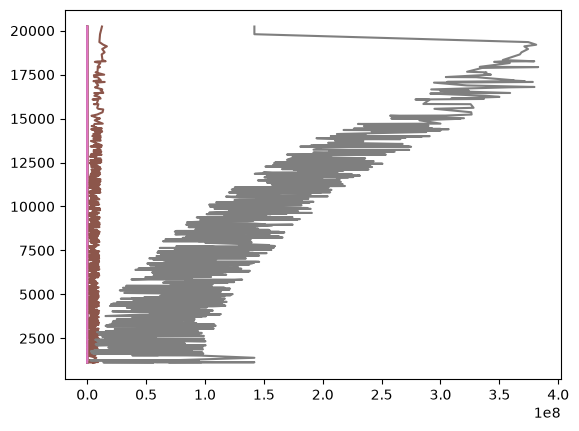

In [119]:
plt.plot(X,y)
plt.show()

In [120]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

In [121]:
ridge = Ridge(alpha=1.0)

In [122]:
ridge.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [123]:
y_pred= ridge.predict(X_test)
print(y_pred)

[ 2819.41313889   -35.14532252  1970.96639812  1198.6651781
 14436.41127574 19769.47882835 11367.25482119  3199.76866487
  5234.66964541  7814.3629613  10975.46251492  6357.06267993
  1363.64402829  2808.90454026  5461.90358434  5836.95763355
 10607.73214294  8265.70751485  8742.63739341  5678.19399207
  6088.68658644  5303.49507993  6228.59827274  6474.14546324
  5964.99088274  5714.10833914  7431.48113271 14925.55143479
  5730.85362615  6208.09814435  5495.23741346  6128.96053822
 10751.73576933  6853.96450728  5382.76913346   557.8112432
  6242.21224816 15466.49838232  7096.17859788  5559.71666901
  8601.96932165  8307.88517416  -510.22327983  8773.82608561
  5542.10542346  2143.2469807   4650.31448986  9005.71780758
 11188.92242354 10115.38597406 13225.48850268  8044.83235413
 11044.69728225  8275.71861688  5018.59359455   -94.28279659
  5454.97965291 11237.54220386  5596.29945951  9195.95341672
 11309.05496481  9934.17238323  7073.20185857  3277.34367917
  9745.50851401  9720.8334

In [124]:
mae = mean_absolute_error(y_test,y_pred)

In [125]:
print(mae)

1303.6375646198394


In [126]:
mse = mean_squared_error(y_test,y_pred)
print(mse)

2864777.046543536


In [127]:
rmse=mse**0.5
print(rmse)

1692.5652266732693


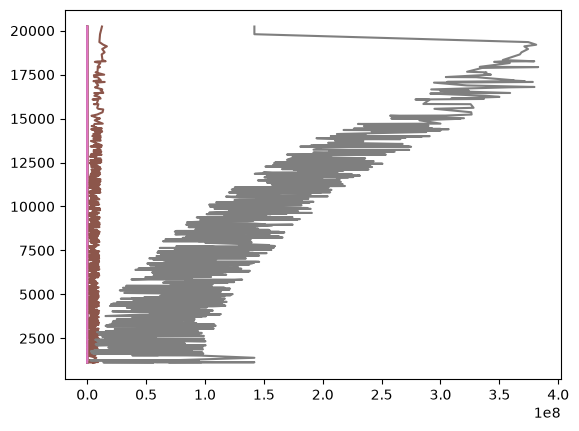

In [128]:
plt.plot(X,y)
plt.show()

In [129]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

In [130]:
lasso = Lasso(alpha=1.0)

In [131]:
lasso.fit(X_train, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [132]:
y_pred= lasso.predict(X_test)
print(y_pred)

[ 2798.69221448   -54.00467258  1955.94104897  1184.267819
 14430.22890063 19750.25819516 11375.43482217  3202.66987582
  5237.4129575   7818.74698281 10979.46525827  6359.13430738
  1342.97837306  2787.75074167  5465.90336973  5839.73794431
 10611.08789869  8275.93194475  8746.02227878  5688.543482
  6094.79053329  5309.9611732   6239.75031537  6485.41709335
  5972.29464312  5711.02225608  7441.85505381 14934.05488794
  5733.2987886   6217.11100857  5507.28946454  6132.73588708
 10760.53874874  6861.82502799  5376.20838637   538.49233209
  6245.10899853 15459.3807486   7101.55487058  5561.95844334
  8602.64444461  8315.36769164  -524.82596179  8775.04760596
  5553.67703984  2123.34919659  4653.66025988  9012.99724708
 11191.82403541 10113.57233813 13220.44493117  8043.77451235
 11048.79972302  8275.19818458  5018.19007259  -108.94675073
  5457.09723559 11242.03607296  5592.53286521  9195.01929208
 11319.08211388  9939.26449098  7080.29344885  3261.24992346
  9747.10701659  9731.548793

In [133]:
mae = mean_absolute_error(y_test,y_pred)
print(mae)
mse = mean_squared_error(y_test,y_pred)
print(mse)
rmse=mse**0.5
print(rmse)

1303.599684432691
2865915.529267311
1692.9015119809278


In [134]:
models = {'Linear': model, 'Ridge': ridge, 'Lasso': lasso}

rows = []
for name, m in models.items():
    p = m.predict(X_test)
    rows.append([name, mean_absolute_error(y_test, p),
                 np.sqrt(mean_squared_error(y_test, p)), r2_score(y_test, p)])
results = pd.DataFrame(rows, columns=['Model', 'MAE', 'RMSE', 'R2']).set_index('Model')
results.round(3)

,MAE,RMSE,R2
Model,,,
Linear,1502.699,1926.763,0.816
Ridge,1303.638,1692.565,0.858
Lasso,1303.600,1692.902,0.858


In [135]:
rows = []
for name, m in models.items():
    tr, te = r2_score(y_train, m.predict(X_train_s)), r2_score(y_test, m.predict(X_test_s))
    rows.append([name, tr, te, tr - te])
bv = pd.DataFrame(rows, columns=['Model', 'Train R2', 'Test R2', 'Gap']).set_index('Model')
bv.round(3)

,Train R2,Test R2,Gap
Model,,,
Linear,-2.316,-2.260,-0.056
Ridge,-3.629,-3.530,-0.098
Lasso,-3.650,-3.555,-0.095


In [136]:
from sklearn.model_selection import GridSearchCV
grids = {
    'Ridge': (Ridge(),  {'alpha': [0.01, 0.1, 1, 10, 100]}),
    'Lasso': (Lasso(),  {'alpha': [0.01, 0.1, 1, 10, 100]})}

tuned = {}
for name, (m, params) in grids.items():
    gs = GridSearchCV(m, params, cv=5, scoring='r2')
    gs.fit(X_train_s, y_train)


In [140]:
import pickle
all_models = {'Linear': model, **tuned}
best_name = max(all_models, key=lambda n: r2_score(y_test, all_models[n].predict(X_test_s)))
best_model = all_models[best_name]
print('Best model:', best_name)
import joblib
joblib.dump(best_model, 'insurance_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
joblib.dump(list(X.columns), 'features.pkl')

Best model: Linear


['features.pkl']